# 5 · Plant Many

Plant a proper test set: **32 itemsets** = 4 sizes (2–5 items) × 4 supports (5%, 1%, 0.2%, 0.05%) × 2 kinds
(*natural* combos a model might half-know, *surprising* ones only our baskets can teach). They share items, and
overlapping plants disturb each other — that's the interesting part.

**Done when:** `my_plant_all` is identical to the reference and my report shows what the baskets really hold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import (
    NATURAL, SUPPORTS, Planted, make_catalog, popularity, background_baskets, default_planted,
    plant_all as reference_plant_all, plant_itemset, planted_report as reference_report, support_of)

catalog = make_catalog()
shares = popularity(catalog)
baskets = background_baskets(100_000, catalog, shares, seed=0)
product_of = {item.name: item.base for item in catalog}
print(f"{len(baskets):,} background baskets")

100,000 background baskets


## The natural sets (hand-picked products, 4 per size)

In [2]:
for size, groups in NATURAL.items():
    print(f"size {size}:")
    for group in groups:
        print("    ", " + ".join(group))
print("\nsupports:", [f"{s:.2%}" for s in SUPPORTS])

size 2:
     Tea Powder + Sugar
     Bread + Butter
     Toothpaste + Toothbrush
     Detergent Powder + Dishwash Bar
size 3:
     Toor Dal + Sona Masoori Rice + Sunflower Oil
     Turmeric Powder + Red Chilli Powder + Coriander Powder
     Milk + Bread + Eggs
     Shampoo Sachet + Soap Bar + Hair Oil
size 4:
     Wheat Flour (Atta) + Sugar + Salt + Sunflower Oil
     Tea Powder + Milk + Glucose Biscuits + Rusk
     Instant Noodles + Potato Chips + Soft Drink + Namkeen Mixture
     Dosa Batter + Coconut Oil + Curry Leaves + Mustard Seeds
size 5:
     Onion + Tomato + Green Chilli + Ginger + Garlic
     Basmati Rice + Biryani Masala + Ghee + Onion + Curd
     Cornflakes + Milk + Banana + Jam + Bread
     Detergent Bar + Phenyl + Floor Cleaner + Toilet Cleaner + Garbage Bags

supports: ['5.00%', '1.00%', '0.20%', '0.05%']


## The plan

`default_planted` fills in SKUs and random cross-category *surprising* sets, under four rules:
1. one SKU per product across all itemsets (otherwise planting one would swap out another's item);
2. no itemset inside another (a part must be at least as common as its whole);
3. chance may supply at most 30% of a target;
4. natural sets that are common by chance get high supports, rare ones low.

In [3]:
planted = default_planted(catalog, shares, baskets, seed=0)

plan = pd.DataFrame([{"support": p.support, "size": len(p.items), "kind": p.kind,
                      "items": " + ".join(p.items)} for p in planted])
print(len(plan), "itemsets\n")
plan.groupby(["support", "kind"]).size().unstack()

32 itemsets



kind,natural,surprising
support,,
0.0005,4,4
0.0020,4,4
0.0100,4,4
0.0500,4,4


In [4]:
pd.set_option("display.max_colwidth", 110)
plan[(plan["support"] == 0.01)].reset_index(drop=True)[["size", "kind", "items"]]

,size,kind,items
0,2,natural,Shuddh Detergent Powder 500 g + Ghar Ghar Dishwash Bar 1 bar
1,2,surprising,Rasoi Royale Biryani Masala 100 g + Rupa Rani Toothbrush 1 brush
2,3,natural,Amulya Milk 500 ml + Crunchy Crust Bread 400 g + Gokul Fresh Eggs 6 pack
3,3,surprising,Brinjal 1 kg + Chai Chaska Soft Drink 2 L + Kesari Cumin Seeds 200 g
4,4,natural,Brew Bazaar Tea Powder 250 g + Amulya Milk 500 ml + Crunchy Crust Glucose Biscuits 400 g + Baker's Basket ...
5,4,surprising,Munch Mela Potato Chips Rs 5 pack + Kesari Chaat Masala sachet 10 g + Rupa Rani Deodorant 100 ml + Surya G...
6,5,natural,Annadata Basmati Rice 5 kg + Rasoi Royale Biryani Masala 100 g + Suryamukhi Ghee 200 g + Onion 1 kg + Nand...
7,5,surprising,Pragati Urad Dal 500 g + Shuddh Toilet Cleaner 500 ml + Gokul Fresh Butter 500 g + Suryamukhi Ghee 200 g +...


## Check the rules myself

`check_plan` returns a list of problems; empty = valid.

In [5]:
def check_plan(planted, background=None):
    """Problems with a plan, as a list of strings. Empty means every rule holds."""
    problems = []

    one_sku = {}                                           # rule 1
    for p in planted:
        for name in p.items:
            if one_sku.setdefault(product_of[name], name) != name:
                problems.append(f"{product_of[name]} appears as both {one_sku[product_of[name]]} and {name}")

    sets = [set(p.items) for p in planted]                 # rule 2
    for i, a in enumerate(sets):
        for j, b in enumerate(sets):
            if i != j and a <= b:
                problems.append(f"{planted[i].items} is contained in {planted[j].items}")

    if background is not None:                             # rule 3
        held_by = {}
        for number, basket in enumerate(background):
            for name in set(basket):
                held_by.setdefault(name, set()).add(number)
        for p in planted:
            chance = len(set.intersection(*(held_by.get(name, set()) for name in p.items))) / len(background)
            if chance > 0.3 * p.support:
                problems.append(f"{p.items}: chance gives {chance:.3%}, over 30% of {p.support:.2%}")
    return problems


print("the plan:", check_plan(planted, baskets) or "no problems")

the plan: no problems


Break it on purpose — a second Tea Powder SKU:

In [6]:
tea = next(p for p in planted if any(product_of[n] == "Tea Powder" for n in p.items))
other_tea = next(i.name for i in catalog if i.base == "Tea Powder" and i.name not in tea.items)
wrong_item = tuple(other_tea if product_of[n] == "Tea Powder" else n for n in tea.items)

for problem in check_plan(planted + [Planted(wrong_item, 0.01, "natural")]):
    print("-", problem)

- Tea Powder appears as both Brew Bazaar Tea Powder 250 g and Chai Chaska Tea Powder 250 g


## Overlap

In [7]:
from collections import Counter

uses = Counter(name for p in planted for name in p.items)
shared = {name: n for name, n in uses.items() if n > 1}
print(f"{len(uses)} distinct items across {len(planted)} itemsets; {len(shared)} of them are in more than one")
print("\nthe most shared:")
for name, n in uses.most_common(4):
    print(f"   {n} itemsets  {name}")

79 distinct items across 32 itemsets; 24 of them are in more than one

the most shared:
   4 itemsets  Crunchy Crust Bread 400 g
   4 itemsets  Shuddh Toilet Cleaner 500 ml
   3 itemsets  Brew Bazaar Tea Powder 250 g
   3 itemsets  Rasoi Royale Biryani Masala 100 g


## Planting them all

Plant one after another with section 4's function, **largest first**, and with `allow_excess=True` (if earlier
plants already pushed a later set over its target, leave it — we can't remove baskets).

In [8]:
def my_plant_all(baskets, planted, catalog, seed=0):
    problems = check_plan(planted)
    if problems:
        raise ValueError("; ".join(problems))
    order = sorted(range(len(planted)), key=lambda i: (-len(planted[i].items), -planted[i].support))
    out = list(baskets)
    for step, i in enumerate(order):
        out = plant_itemset(out, planted[i], catalog, seed=seed + step, allow_excess=True)
    return out


mine = my_plant_all(baskets, planted, catalog, seed=0)
print("identical to the reference:", mine == reference_plant_all(baskets, planted, catalog, seed=0))

identical to the reference: True


## Asked for vs got

In [9]:
def my_report(baskets, planted):
    rows = []
    for p in planted:
        held = sum(set(p.items) <= set(basket) for basket in baskets)
        rows.append({"kind": p.kind, "size": len(p.items), "target": p.support,
                     "realised": held / len(baskets), "items": " + ".join(p.items)})
    return pd.DataFrame(rows)

report = my_report(mine, planted)
report["off_by"] = report["realised"] / report["target"] - 1

exact = (report["off_by"].abs() < 0.01).sum()
print(f"{exact} of {len(report)} itemsets are within 1% of their target\n")
report.loc[report["off_by"].abs() >= 0.01, ["kind", "size", "target", "realised", "off_by", "items"]]

29 of 32 itemsets are within 1% of their target



,kind,size,target,realised,off_by,items
0,natural,2,0.050,0.05086,0.0172,Crunchy Crust Bread 400 g + Gokul Fresh Butter 500 g
10,natural,3,0.010,0.01011,0.0110,Amulya Milk 500 ml + Crunchy Crust Bread 400 g + Gokul Fresh Eggs 6 pack
16,natural,2,0.002,0.00664,2.3200,Brew Bazaar Tea Powder 250 g + Chai Chaska Sugar 1 kg


My report should agree with the package's `planted_report`:

In [10]:
ref = pd.DataFrame(reference_report(mine, planted))
print("realised supports match the reference report:", np.allclose(report["realised"].values, ref["realised"].values))

realised supports match the reference report: True


A 0.20% tea + sugar pair ended up at 0.66%. Why? Look at where its items sit in other itemsets:

In [11]:
worst = report["off_by"].idxmax()
pair = planted[worst]
print("the worst:", pair.items, f"target {pair.support:.2%}\n")

for other in planted:
    shared_items = set(pair.items) & set(other.items)
    if other is not pair and shared_items:
        print(f"  shares {sorted(shared_items)[0]!r:36} with a {other.support:.2%} {other.kind} set of {len(other.items)}")

the worst: ('Brew Bazaar Tea Powder 250 g', 'Chai Chaska Sugar 1 kg') target 0.20%

  shares 'Brew Bazaar Tea Powder 250 g'       with a 5.00% surprising set of 3
  shares 'Chai Chaska Sugar 1 kg'             with a 5.00% natural set of 4
  shares 'Brew Bazaar Tea Powder 250 g'       with a 1.00% natural set of 4


In [12]:
a = next(p for p in planted if pair.items[0] in p.items and p.support == 0.05)
b = next(p for p in planted if pair.items[1] in p.items and p.support == 0.05)
both = support_of(mine, set(a.items) | set(b.items))
print(f"baskets holding the whole 5% triple AND the whole 5% four-set: {both:.3%}")
print(f"each is in 5% of baskets, so if independent: {0.05 * 0.05:.3%}")

baskets holding the whole 5% triple AND the whole 5% four-set: 0.269%
each is in 5% of baskets, so if independent: 0.250%


The tea is in one 5% set and the sugar in another; by luck 0.27% of baskets get both — already above the 0.2%
target. Each plant is right on its own; together they overshoot, and planting can't take baskets away. Overlap puts
a floor under the rarest itemsets.

## Does the planting order matter?

In [13]:
def plant_in_order(order):
    out = list(baskets)
    for step, i in enumerate(order):
        out = plant_itemset(out, planted[i], catalog, seed=step, allow_excess=True)
    r = my_report(out, planted)
    off = r["realised"] / r["target"] - 1
    return {"misses (>1% off)": int((off.abs() > 0.01).sum()), "worst overshoot": f"{off.max():+.0%}"}

orders = {
    "large first (ours)": sorted(range(len(planted)), key=lambda i: (-len(planted[i].items), -planted[i].support)),
    "rarest first": sorted(range(len(planted)), key=lambda i: (planted[i].support, len(planted[i].items))),
    "as listed": list(range(len(planted))),
}
pd.DataFrame({name: plant_in_order(order) for name, order in orders.items()}).T

,misses (>1% off),worst overshoot
large first (ours),3,+232%
rarest first,6,+290%
as listed,3,+225%


Order changes the number of misses a bit, but the worst overshoot belongs to the plan, not the order.

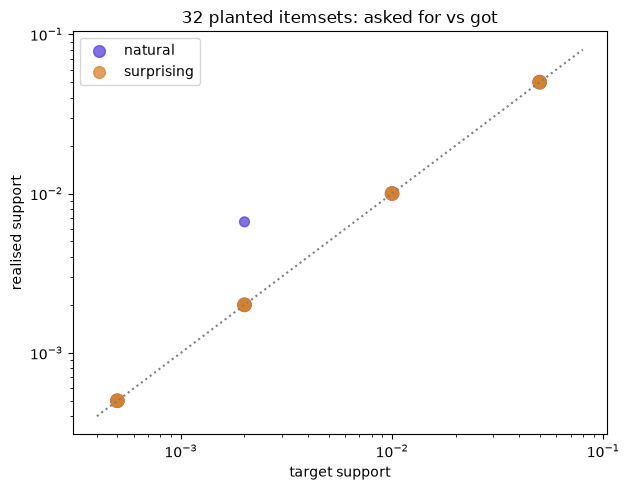

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 5))
colors = {"natural": "#5b3de0", "surprising": "#d9822b"}
for kind, group in report.groupby("kind"):
    ax.scatter(group["target"], group["realised"], s=22 + 14 * group["size"], color=colors[kind], alpha=0.75, label=kind)
low, high = 0.0004, 0.08
ax.plot([low, high], [low, high], color="grey", linestyle=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("target support"); ax.set_ylabel("realised support")
ax.set_title("32 planted itemsets: asked for vs got")
ax.legend()
plt.tight_layout()
plt.show()

## How much of the shop did we touch?

In [15]:
touched = np.mean([a != b for a, b in zip(baskets, mine)])
counts = pd.Series([sum(name in {n for p in planted for n in p.items} for name in set(basket)) for basket in mine])

print(f"{touched:.0%} of the baskets were rewritten by planting")
print(f"{(counts == 0).mean():.0%} of baskets hold no planted item at all")
print(f"on average a basket holds {counts.mean():.1f} of the 79 planted items (it held {np.mean([sum(name in {n for p in planted for n in p.items} for name in set(b)) for b in baskets]):.1f} before)")

40% of the baskets were rewritten by planting
16% of baskets hold no planted item at all


on average a basket holds 3.1 of the 79 planted items (it held 1.4 before)


40% of baskets rewritten — far more structure than a real shop, chosen so the rarest patterns are still there.
Worth remembering when reading scores later. The model gets scored against what the baskets *hold*, not the plan;
section 6 counts it exactly.

## Try it: other seeds

In [16]:
for seed in range(5):
    try:
        plan_s = default_planted(catalog, shares, baskets, seed=seed)
    except ValueError as error:
        print(f"seed {seed}: no valid plan ({error})")
        continue
    result = my_report(reference_plant_all(baskets, plan_s, catalog, seed=seed), plan_s)
    off = result["realised"] / result["target"] - 1
    print(f"seed {seed}: {int((off.abs() > 0.01).sum()):>2} of 32 more than 1% off, worst overshoot {off.max():+.0%}")

seed 0:  3 of 32 more than 1% off, worst overshoot +232%


seed 1:  0 of 32 more than 1% off, worst overshoot +0%


seed 2:  2 of 32 more than 1% off, worst overshoot +29%
seed 3: no valid plan (the natural set ('Shuddh Detergent Powder 500 g', 'Sparkle Home Dishwash Bar pack of 3') is too common by chance, or overlaps another, at support 0.002)


seed 4:  0 of 32 more than 1% off, worst overshoot +0%


## What I built
A plan checker, `my_plant_all` (identical to the reference), and a report of asked-for vs realised support. 29 of
32 land within 1%; overlap makes a 0.2% pair unreachable (0.66%).

## Test yourself

**1. Why must a product keep the same SKU in every planted itemset?**
Planting swaps out other SKUs of a planted product. If tea were one brand in itemset A and another in itemset B,
planting B would replace A's tea in those baskets and undo part of A.

**2. Why did the 0.20% tea + sugar pair end up at 0.66%?**
Its tea is in one 5% itemset and its sugar in a different 5% itemset. By chance some baskets get both big sets, and
every such basket holds the pair, which already exceeds 0.2%. Planting can only add, so it can't be pulled back down.

**3. Why is the model scored against what the baskets hold rather than the plan?**
The plan is what we asked for, but overlaps and chance change the real counts (and create extra frequent itemsets).
The truth is whatever is actually in the data, so we count it exactly instead of trusting the plan.

## My notes

Planting 32 overlapping itemsets mostly lands exactly (29 of 32), but items shared between sets push some rare ones over target. Surprising: a 0.2% pair came out at 0.66% purely because its two items each sat in a different 5% set.